In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Non-finite KL counts by approximation:
    Gaussian  Skewed Gaussian  Student-t  Skewed Student-t
n                                                         
2         77               77          0                 0
4         10               10          0                 0
8          1                1          0                 0
16         0                0          0                 0
32         0                0          0                 0
64         0                0          0                 0

Non-finite KL percentages by approximation:
    Gaussian  Skewed Gaussian  Student-t  Skewed Student-t
n                                                         
2       15.4             15.4        0.0               0.0
4        2.0              2.0        0.0               0.0
8        0.2              0.2        0.0               0.0
16       0.0              0.0        0.0               0.0
32       0.0              0.0        0.0               0.0
64       0.0              0.0  

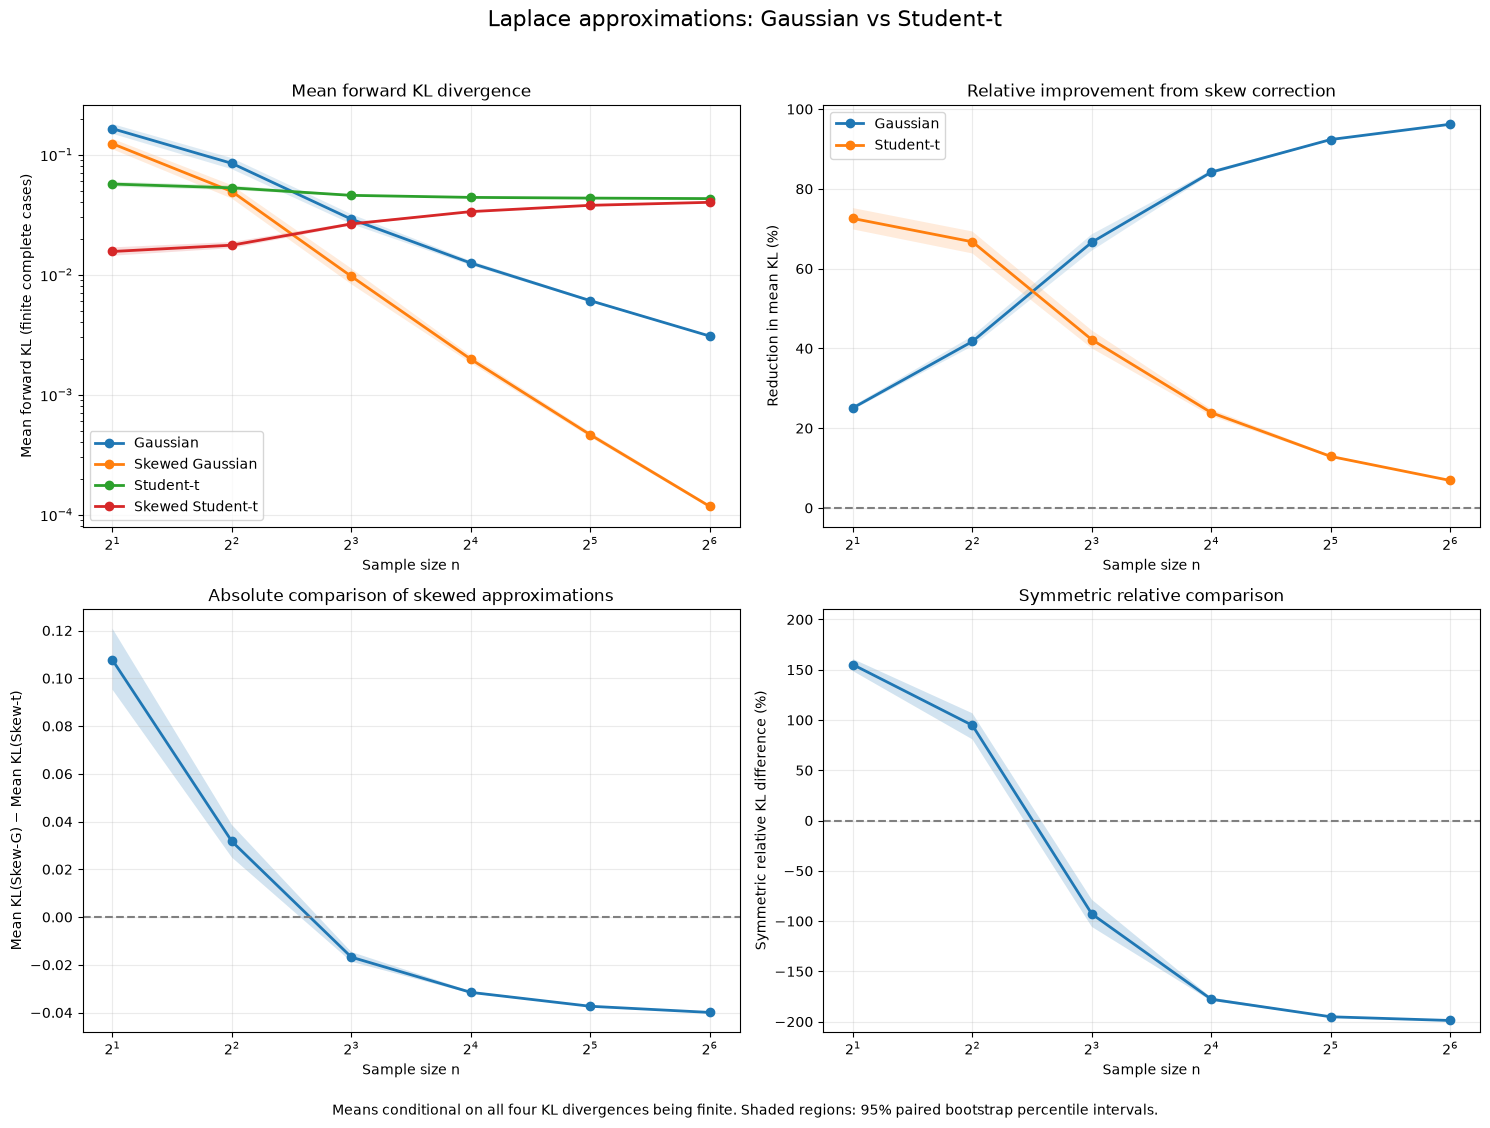

In [15]:

# ============================================================
# 1. LOAD AND PREPARE DATA
# ============================================================

df = pd.read_csv("simulations_laplace_poisson")

df["family"] = df["family"].str.strip().str.lower()

# Handle boolean values consistently, including CSV strings
if df["skewed"].dtype != bool:
    df["skewed"] = (
        df["skewed"].astype(str).str.lower()
        .map({"true": True, "false": False})
    )

df["kl"] = pd.to_numeric(df["kl"], errors="coerce")

if df["skewed"].isna().any():
    raise ValueError("Invalid values in the 'skewed' column.")

# Every (n, replicate, family, skewed) must be unique
keys = ["n", "replicate", "family", "skewed"]

if df.duplicated(keys).any():
    raise ValueError("Duplicate simulation results detected.")

# Pivot: one row per replicate, four KL values per row
wide = df.pivot(
    index=["n", "replicate"],
    columns=["family", "skewed"],
    values="kl"
)

# Fixed column order:
# G = Gaussian, SG = Skewed Gaussian
# T = Student-t, ST = Skewed Student-t
method_names = [
    "Gaussian",
    "Skewed Gaussian",
    "Student-t",
    "Skewed Student-t"
]

expected_columns = pd.MultiIndex.from_tuples([
    ("gaussian", False),
    ("gaussian", True),
    ("student_t", False),
    ("student_t", True)
], names=["family", "skewed"])

wide = wide.reindex(columns=expected_columns)
wide.columns = method_names

# ============================================================
# DIAGNOSTIC — NON-FINITE KL BY APPROXIMATION
# ============================================================

# Each entry is True when the KL is NaN, +inf, or -inf
nonfinite = ~np.isfinite(wide)

# Counts by sample size and approximation
missing_counts = nonfinite.groupby(level="n").sum()

# Percentage of replicates affected
total_counts = wide.groupby(level="n").size()

missing_pct = missing_counts.div(total_counts, axis=0) * 100

print("Non-finite KL counts by approximation:")
print(missing_counts.to_string())

print("\nNon-finite KL percentages by approximation:")
print(missing_pct.round(2).to_string())

# Keep only replicates where all four KL values are finite
finite_mask = np.isfinite(wide.to_numpy()).all(axis=1)
paired = wide.loc[finite_mask].copy()

# Report how many replicates were retained
n_total = wide.groupby(level="n").size()
n_retained = paired.groupby(level="n").size()

retention = pd.DataFrame({
    "total": n_total,
    "retained": n_retained
}).fillna(0).astype(int)

retention["excluded"] = retention["total"] - retention["retained"]
retention["excluded_pct"] = (
    100 * retention["excluded"] / retention["total"]
)

print("Complete-case filtering:")
print(retention.to_string())
print()

if paired.empty:
    raise ValueError("No complete finite replicates available.")


# ============================================================
# 2. DEFINE STATISTICS
# ============================================================

def calculate_statistics(means):
    """
    means: array of shape (B, 4), where columns are
           G, SG, T, ST.

    Returns: array of shape (B, 8):
        0-3: mean KL for the four methods
        4: Gaussian skew improvement (%)
        5: Student-t skew improvement (%)
        6: absolute difference SG - ST
        7: symmetric relative difference (%)
    """
    G  = means[:, 0]
    SG = means[:, 1]
    T  = means[:, 2]
    ST = means[:, 3]

    gain_gaussian = 100 * (1 - SG / G)
    gain_student = 100 * (1 - ST / T)

    absolute_difference = SG - ST

    symmetric_difference = (
        200 * (SG - ST) / (SG + ST)
    )

    return np.column_stack([
        means,
        gain_gaussian,
        gain_student,
        absolute_difference,
        symmetric_difference
    ])


# ============================================================
# 3. PAIRED BOOTSTRAP
# ============================================================

rng_bootstrap = np.random.default_rng(2026)

n_bootstrap = 2000
confidence_level = 0.95
alpha = (1 - confidence_level) / 2

stat_names = [
    "Gaussian",
    "Skewed Gaussian",
    "Student-t",
    "Skewed Student-t",
    "gain_gaussian",
    "gain_student",
    "absolute_difference",
    "symmetric_difference"
]

records = []

for n, group in paired.groupby(level="n"):

    values = group.to_numpy(dtype=float)  # (R, 4)
    R = len(values)

    # Point estimates: ratios of means, not means of ratios
    means = values.mean(axis=0, keepdims=True)

    if np.any(means <= 0):
        raise ValueError(
            f"Nonpositive mean KL at n={n}; "
            "relative statistics are undefined."
        )

    point = calculate_statistics(means)[0]

    # Resample entire replicate rows
    indices = rng_bootstrap.integers(
        low=0,
        high=R,
        size=(n_bootstrap, R)
    )

    bootstrap_values = values[indices]   # (B, R, 4)
    bootstrap_means = bootstrap_values.mean(axis=1)

    bootstrap_stats = calculate_statistics(bootstrap_means)

    lower = np.quantile(
        bootstrap_stats, alpha, axis=0
    )

    upper = np.quantile(
        bootstrap_stats, 1 - alpha, axis=0
    )

    row = {"n": n, "n_replicates": R}

    for j, name in enumerate(stat_names):
        row[name] = point[j]
        row[f"{name}_lower"] = lower[j]
        row[f"{name}_upper"] = upper[j]

    records.append(row)

summary = pd.DataFrame(records).sort_values("n")

print("Summary statistics:")
print(summary[[
    "n",
    "n_replicates",
    "Gaussian",
    "Skewed Gaussian",
    "Student-t",
    "Skewed Student-t",
    "gain_gaussian",
    "gain_student",
    "absolute_difference",
    "symmetric_difference"
]].round(5).to_string(index=False))


# ============================================================
# 4. PLOT ALL FOUR PANELS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

x = summary["n"].to_numpy()


# PANEL 1 — MEAN KL DIVERGENCE

ax = axes[0, 0]

for name in method_names:
    ax.plot(
        x,
        summary[name],
        marker="o",
        linewidth=2,
        label=name
    )

    ax.fill_between(
        x,
        summary[f"{name}_lower"],
        summary[f"{name}_upper"],
        alpha=0.15
    )

ax.set_xscale("log", base=2)
ax.set_yscale("log")

ax.set_title("Mean forward KL divergence")
ax.set_xlabel("Sample size n")
ax.set_ylabel("Mean forward KL (finite complete cases)")
ax.legend()
ax.grid(alpha=0.25)


# PANEL 2 — RELATIVE IMPROVEMENT FROM SKEW CORRECTION

ax = axes[0, 1]

for key, label in [
    ("gain_gaussian", "Gaussian"),
    ("gain_student", "Student-t")
]:
    ax.plot(
        x,
        summary[key],
        marker="o",
        linewidth=2,
        label=label
    )

    ax.fill_between(
        x,
        summary[f"{key}_lower"],
        summary[f"{key}_upper"],
        alpha=0.15
    )

ax.axhline(0, color="gray", linestyle="--")

ax.set_xscale("log", base=2)
ax.set_title("Relative improvement from skew correction")
ax.set_xlabel("Sample size n")
ax.set_ylabel("Reduction in mean KL (%)")
ax.legend()
ax.grid(alpha=0.25)


# PANEL 3 — ABSOLUTE COMPARISON OF SKEWED APPROXIMATIONS

ax = axes[1, 0]

key = "absolute_difference"

ax.plot(
    x,
    summary[key],
    marker="o",
    linewidth=2
)

ax.fill_between(
    x,
    summary[f"{key}_lower"],
    summary[f"{key}_upper"],
    alpha=0.2
)

ax.axhline(0, color="gray", linestyle="--")

ax.set_xscale("log", base=2)
ax.set_title("Absolute comparison of skewed approximations")
ax.set_xlabel("Sample size n")
ax.set_ylabel("Mean KL(Skew-G) − Mean KL(Skew-t)")
ax.grid(alpha=0.25)


# PANEL 4 — SYMMETRIC RELATIVE COMPARISON

ax = axes[1, 1]

key = "symmetric_difference"

ax.plot(
    x,
    summary[key],
    marker="o",
    linewidth=2
)

ax.fill_between(
    x,
    summary[f"{key}_lower"],
    summary[f"{key}_upper"],
    alpha=0.2
)

ax.axhline(0, color="gray", linestyle="--")

ax.set_xscale("log", base=2)
ax.set_ylim(-210, 210)

ax.set_title("Symmetric relative comparison")
ax.set_xlabel("Sample size n")
ax.set_ylabel("Symmetric relative KL difference (%)")
ax.grid(alpha=0.25)


# FIGURE FORMATTING

fig.suptitle(
    "Laplace approximations: Gaussian vs Student-t",
    fontsize=16,
    y=1.01
)

fig.text(
    0.5, 0.005,
    "Means conditional on all four KL divergences being finite. "
    "Shaded regions: 95% paired bootstrap percentile intervals.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.025, 1, 0.99])
plt.show()
